# BTC 5 minutos · Análisis comparativo de modelos

Este notebook reúne datos, comparación de modelos, optimización, estabilidad y conclusiones. **Las gráficas y tablas ya están guardadas y pueden verse sin ejecutar celdas.** Resultados del 17 de noviembre de 2026.

**Mejor candidato exploratorio:** XGBoost con 50 rezagos y variables adicionales, 54.64% de acierto medio frente a 51.99% de referencia. No hay mejora consistente en los tres periodos ni evidencia de rentabilidad. El test final permanece reservado.

Para actualizar las gráficas con los experimentos existentes, selecciona el kernel del entorno `.venv` y ejecuta todas las celdas. Se necesita `ipykernel` para registrar ese entorno en Jupyter/VS Code. La actualización visual usa resultados locales; no consulta APIs ni entrena modelos. Ajusta `PROYECTO` en la siguiente celda si moviste el repositorio.

El ejemplo XAU/USD se tomó como referencia de presentación. Aquí se conserva BTC 5 m, el 80/20 cronológico y la optimización autorizada.


In [ ]:
from pathlib import Path
import re
from IPython.display import display, HTML, SVG

# Usar la carpeta que contiene data/, models/ y config/.
PROYECTO = Path(r"C:/Users/crist/OneDrive/Escritorio/Bot-financiero-polymarket")
if not PROYECTO.is_dir():
    PROYECTO = Path.cwd()

ORIGINAL = PROYECTO / "models/research_notebook_20261117/results.json"
OPTIMIZADO = PROYECTO / "models/optimized_research_20261117/results.json"
DATOS = PROYECTO / "data/history_7d_20261117/records.jsonl"
print("Proyecto:", PROYECTO)


Proyecto: C:\Users\crist\OneDrive\Escritorio\Bot-financiero-polymarket


## Preparación del análisis

La siguiente celda contiene las funciones del análisis dentro del notebook para que el archivo sea independiente del script `.py`. Puede contraerse durante la lectura. Conserva las verificaciones de correspondencia entre predicciones, etiquetas y test reservado.


In [ ]:
"""Análisis visual del proyecto BTC 5m en un único punto de entrada.

Uso desde el repositorio:
    python analisis_modelos.py
    python analisis_modelos.py --sin-abrir
    .venv/Scripts/python.exe analisis_modelos.py --reentrenar

El modo normal usa resultados guardados y solo la biblioteca estándar.
Produce UN HTML autónomo, sin CDN ni internet. --reentrenar reutiliza los motores
del proyecto y guarda sus artefactos bajo una sola carpeta local de ejecución.
No evalúa el test final ni activa modelos. El ejemplo XAU/USD aportado se toma
como referencia de presentación; se conservan BTC 5m y el diseño vigente.
"""
import argparse
from datetime import datetime, timezone
import html
import json
import math
from pathlib import Path
import random
import statistics as stats
import webbrowser


def read_json(path):
    with Path(path).open(encoding='utf-8-sig') as handle:
        return json.load(handle)


def esc(value):
    return html.escape(str(value))


def table(headers, rows):
    return '<div class="scroll"><table><thead><tr>'+''.join('<th>'+esc(h)+'</th>' for h in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+esc(v)+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table></div>'


def bars(labels, values, title, suffix='', reference=None):
    if not labels or len(labels) != len(values) or any(not math.isfinite(v) for v in values):
        raise ValueError('Valores inválidos para gráfica')
    left, width, step = 235, 550, 28
    upper = max(values+[reference or 0])*1.12 or 1
    height = 55+len(labels)*step
    parts = [f'<svg viewBox="0 0 870 {height}" role="img" aria-label="{esc(title)}"><title>{esc(title)}</title>']
    for i,(label,value) in enumerate(zip(labels,values)):
        y=32+i*step
        parts += [f'<text x="225" y="{y+14}" text-anchor="end">{esc(label)}</text>',
                  f'<rect x="{left}" y="{y}" width="{width*value/upper:.2f}" height="19" rx="3" fill="#3477b8"/>',
                  f'<text x="{left+width*value/upper+7:.2f}" y="{y+14}">{value:.2f}{esc(suffix)}</text>']
    if reference is not None:
        x=left+width*reference/upper
        parts += [f'<path d="M{x:.2f},24 V{height-12}" stroke="#c05a20" stroke-width="2" stroke-dasharray="5 4"/>',
                  f'<text x="{x:.2f}" y="16" fill="#a34b18">Referencia {reference:.2f}{esc(suffix)}</text>']
    return ''.join(parts)+'</svg>'


def lines(series, title, y_label):
    # Cada observación se conserva; los ejes indican índice temporal y unidades.
    all_values=[v for _,values,_ in series for v in values]
    low,high=min(all_values),max(all_values)
    padding=(high-low)*0.08 or 1
    low-=padding; high+=padding
    n=max(len(values) for _,values,_ in series)
    def point(i,v): return 75+760*i/max(1,n-1), 300-240*(v-low)/(high-low)
    result=[f'<svg viewBox="0 0 870 365" role="img" aria-label="{esc(title)}"><title>{esc(title)}</title>']
    for k in range(5):
        value=low+(high-low)*k/4
        _,y=point(0,value)
        result += [f'<path d="M75,{y} H835" stroke="#dde4eb"/>',f'<text x="68" y="{y+4}" text-anchor="end">{value:.1f}</text>']
    for name,values,color in series:
        pts=' '.join(f'{x:.2f},{y:.2f}' for x,y in (point(i,v) for i,v in enumerate(values)))
        result.append(f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="1.3"><title>{esc(name)}</title></polyline>')
    for i in (0,(n-1)//2,n-1):
        x,_=point(i,low)
        result.append(f'<text x="{x}" y="321" text-anchor="middle">{i+1}</text>')
    result += [f'<text x="75" y="20">{esc(y_label)}</text>','<text x="455" y="350" text-anchor="middle">Observación de validación en orden temporal</text>']
    return ''.join(result)+'</svg><p>'+ ' · '.join(f'<span style="color:{c}">● {esc(name)}</span>' for name,_,c in series)+'</p>'


def moving_mean(values, window=60):
    return [100*stats.mean(values[max(0,i-window+1):i+1]) for i in range(len(values))]


def paired_block_interval(differences, repetitions=2000, block=24):
    """Intervalo descriptivo por bloques de unas 2 h; NO corrige selección de 60 modelos."""
    rng=random.Random(123)
    estimates=[]
    for _ in range(repetitions):
        sample=[]
        while len(sample)<len(differences):
            start=rng.randrange(len(differences))
            sample.extend(differences[(start+j)%len(differences)] for j in range(block))
        estimates.append(stats.mean(sample[:len(differences)])*100)
    estimates.sort()
    return estimates[int(.025*repetitions)],estimates[int(.975*repetitions)]


def generate(original_path, optimized_path, history_path, output):
    original,optimized=read_json(original_path),read_json(optimized_path)
    if original.get('final_test_evaluated') is not False or optimized.get('final_test_evaluated') is not False:
        raise ValueError('El informe requiere experimentos que conserven el test final reservado')
    rows=[]
    for name,item in original['models'].items():
        if item.get('status')!='trained_research_only': continue
        metric=item['validation_metrics']
        rows.append((name,metric,item['train_metrics'],item.get('warnings',[])))
    rows.sort(key=lambda r:(-r[1]['up_down_accuracy_tie_is_up'],r[1]['rmse']))
    ranking=sorted(optimized['trials'],key=lambda t:(-t['mean_accuracy'],t['mean_rmse']))
    selected=next(t for t in ranking if t['configuration']==optimized['best_research_configuration'])
    oof_path=Path(optimized_path).parent/(selected['configuration']['name']+'_oof.jsonl')
    predictions=[json.loads(line) for line in oof_path.read_text(encoding='utf-8').splitlines() if line]
    n=len(predictions)
    if n!=sum(f['n'] for f in selected['folds']): raise ValueError('Predicciones y métricas tienen tamaños distintos')
    actual=[p['y'] for p in predictions]; predicted=[p['prediction'] for p in predictions]
    correct=[int((a>=0)==(b>=0)) for a,b in zip(actual,predicted)]
    baseline_correct=[]
    fold_scores=[]
    for fold in range(len(selected['folds'])):
        subset=[p for p in predictions if p['fold']==fold]
        accuracy=stats.mean(int((p['y']>=0)==(p['prediction']>=0)) for p in subset)
        if abs(accuracy-selected['folds'][fold]['up_down_accuracy_tie_is_up'])>1e-10:
            raise ValueError('Acierto guardado no coincide con predicciones')
        # Recuperar la dirección de la referencia verificando el acierto guardado.
        expected=optimized['folds'][fold]['majority_baseline_accuracy']
        up_rate=stats.mean(p['y']>=0 for p in subset)
        if abs(up_rate-expected)<1e-10: majority_up=True
        elif abs(1-up_rate-expected)<1e-10: majority_up=False
        else: raise ValueError('No se pudo reconstruir la referencia del bloque')
        baseline_correct.extend(int((p['y']>=0)==majority_up) for p in subset)
        fold_scores.append((fold+1,len(subset),100*accuracy,100*expected))
    differences=[a-b for a,b in zip(correct,baseline_correct)]
    lower,upper=paired_block_interval(differences)
    confusion=[[0,0],[0,0]]
    for a,p in zip(actual,predicted): confusion[int(a>=0)][int(p>=0)]+=1
    errors=[p-a for p,a in zip(predicted,actual)]
    history=[json.loads(l) for l in Path(history_path).read_text(encoding='utf-8').splitlines() if l]
    targets={r['slug']:r['final_price']-r['price_to_beat'] for r in history}
    if len({p['slug'] for p in predictions})!=n:
        raise ValueError('Hay mercados duplicados en las predicciones de validación')
    for row in predictions:
        if row['slug'] not in targets or not math.isclose(row['y'],targets[row['slug']],abs_tol=1e-8):
            raise ValueError('Predicciones e historial no corresponden al mismo objetivo')
        if row['slug'].rsplit('-',1)[1].isdigit() and int(row['slug'].rsplit('-',1)[1])>=datetime.fromisoformat(optimized['final_test_start']).timestamp():
            raise ValueError('Una predicción corresponde al test final reservado')
    dates=[datetime.fromtimestamp(int(p['slug'].rsplit('-',1)[1]),timezone.utc).isoformat() for p in predictions]
    top=ranking[:12]
    baseline=100*stats.mean(f['majority_baseline_accuracy'] for f in optimized['folds'])
    sections=[]
    def section(title,body): sections.append('<section><h2>'+esc(title)+'</h2>'+body+'</section>')
    section('1. Datos y alcance',f'<p>{len(history):,} mercados históricos auditados. Predicción BTC Up/Down a 5 minutos. {original["samples"]:,} ventanas; {optimized["final_test_samples"]} ejemplos finales reservados.</p><p>Objetivo: finalPrice − priceToBeat (USD). La disponibilidad histórica usa closedTime como aproximación. Los resultados son exploratorios; faltan verificación prospectiva, calibración y rentabilidad Paper.</p>')
    section('2. Nueve modelos del notebook · misma validación interna',
        bars([r[0] for r in rows],[100*r[1]['up_down_accuracy_tie_is_up'] for r in rows],'Acierto de modelos originales','%',100*original['validation_majority_baseline_accuracy'])+
        bars([r[0] for r in rows],[r[1]['rmse'] for r in rows],'RMSE de modelos originales',' USD')+
        table(['Modelo','Acierto TR','Acierto VA','RMSE VA USD','MAE VA USD','Sesgo','Correlación'],
        [(name,f"{100*tr['up_down_accuracy_tie_is_up']:.2f}%",f"{100*m['up_down_accuracy_tie_is_up']:.2f}%",f"{m['rmse']:.2f}",f"{m['mae']:.2f}",f"{m['directional_bias']:.3f}" if m['directional_bias'] is not None else 'No definido',f"{m['pearson_correlation']:.3f}" if m['pearson_correlation'] is not None else 'No definida') for name,m,tr,_ in rows])+
        '<p>Menor RMSE es mejor para magnitud; mayor acierto es mejor para dirección. Un gran acierto TR y pequeño acierto VA sugiere sobreajuste.</p>'+''.join('<p class="warning">'+esc(name+': '+warning)+'</p>' for name,_,_,warnings in rows for warning in warnings))
    section('3. Optimización · tres bloques temporales',
        '<p>Las 60 configuraciones se evalúan en otros periodos que los nueve modelos originales. Comparar aquí dentro del mismo experimento. Ranking por acierto medio; RMSE como desempate.</p>'+
        bars([t['configuration']['name'] for t in top],[100*t['mean_accuracy'] for t in top],'Mejores 12 configuraciones','%',baseline)+
        '<details><summary>Tabla completa de 60 configuraciones</summary>'+table(['Configuración','Acierto medio','RMSE medio USD','Mejora pp','Supera referencia en todos los bloques'],[(t['configuration']['name'],f"{100*t['mean_accuracy']:.2f}%",f"{t['mean_rmse']:.2f}",f"{100*t['mean_lift']:+.2f}",'Sí' if t['positive_lift_all_folds'] else 'No') for t in ranking])+'</details>')
    section('4. Candidato y estabilidad', '<p>Candidato exploratorio: <strong>'+esc(selected['configuration']['name'])+'</strong>.</p>'+
        table(['Bloque','N','Acierto candidato','Referencia','Mejora pp'],[(k,n,f'{a:.2f}%',f'{b:.2f}%',f'{a-b:+.2f}') for k,n,a,b in fold_scores])+
        f'<p>Intervalo descriptivo de la mejora: <strong>{lower:+.2f} a {upper:+.2f} pp</strong> (bootstrap pareado, 2,000 repeticiones, bloques de 24 mercados). Conserva dependencia local aproximada; no corrige la selección entre 60 candidatos ni prueba significación. No implica probabilidad de éxito futuro.</p>'+
        lines([('Candidato · ventana 60',moving_mean(correct),'#3477b8'),('Referencia · ventana 60',moving_mean(baseline_correct),'#c05a20')],'Acierto móvil','Acierto %')+
        '<p>Los primeros 59 valores usan ventanas parciales. Fechas UTC: '+esc(dates[0])+' a '+esc(dates[-1])+'.</p>')
    section('5. Predicción frente al resultado · candidato',
        '<p>Últimas 150 observaciones de validación, nunca del test final. Se grafica diferencia de precio, no precio absoluto de BTC ni probabilidad.</p>'+
        lines([('Real',actual[-150:],'#1b8c73'),('Estimado',predicted[-150:],'#8555aa')],'Real frente a predicción','Diferencia USD')+
        lines([('Error = estimado − real',errors[-150:],'#c05a20')],'Error temporal','Error USD')+
        table(['Resultado real / Predicción','Down','Up'],[['Down',*confusion[0]],['Up',*confusion[1]]])+
        '<p>Filas: resultado oficial; columnas: signo predicho. Igualdad se asigna a Up.</p>')
    stable=sum(t['positive_lift_all_folds'] for t in ranking)
    section('6. Lectura del resultado y siguiente decisión',
        f'<p><strong>{stable} de {len(ranking)} configuraciones superaron a la referencia en los tres bloques.</strong> El candidato es una hipótesis de investigación; el test final continúa reservado. No se demostró ganancia neta: faltan precios de ejecución y costos históricos para medirla.</p>'+
        '<p>Prioridad: registrar datos en vivo con hora real de recepción y evaluar el candidato hacia adelante. Reentrenamiento automático y compras requieren integrar ese flujo con la simulación y validar probabilidades. Seguir optimizando sobre los mismos periodos puede sobreajustar la selección.</p>')
    document='''<!doctype html><html lang="es"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>BTC 5m · Análisis de modelos</title><style>
body{font:16px/1.55 system-ui,sans-serif;background:#edf2f7;color:#192b3b;margin:0}main{max-width:1120px;margin:auto;padding:32px}header,section{background:white;border-radius:12px;padding:26px;margin-bottom:22px;box-shadow:0 2px 9px #1830470b}h1{font-size:32px;margin:0}h2{font-size:23px;margin:0 0 18px}p{max-width:95ch}.badge{color:#a34b18;font-weight:700}.scroll{overflow-x:auto}table{border-collapse:collapse;width:100%;font-size:14px}th,td{text-align:left;padding:10px;border-bottom:1px solid #dce5ee}th{background:#eef4f9}svg{width:100%;height:auto;min-width:580px}svg text{font:12px system-ui}section{overflow-x:auto}.warning{padding:10px;background:#fff2df}summary{cursor:pointer;font-weight:600}footer{font-size:13px;color:#536778}@media print{body{background:white}section{box-shadow:none;break-inside:avoid}details{display:block}}</style><main><header><p class="badge">INVESTIGACIÓN · TEST FINAL RESERVADO</p><h1>BTC 5m · Comparación de modelos</h1><p>Datos → modelos originales → optimización → estabilidad → predicciones → conclusión.</p></header>'''+''.join(sections)+'<footer>Generado localmente el '+esc(datetime.now(timezone.utc).isoformat())+' · Gráficas SVG incluidas; sin servicios externos.</footer></main></html>'
    output=Path(output)
    output.parent.mkdir(parents=True,exist_ok=True)
    output.write_text(document,encoding='utf-8')
    print(f'Informe: {output.resolve()}')
    print(f'Candidato: {selected["configuration"]["name"]}; acierto CV {100*stats.mean(correct):.2f}%; intervalo descriptivo de mejora [{lower:.2f}, {upper:.2f}] pp')
    return output




In [ ]:
# Regenerar el análisis desde los resultados guardados.
requeridos = [ORIGINAL, OPTIMIZADO, DATOS]
faltantes = [str(p) for p in requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan artefactos locales: " + "; ".join(faltantes))

informe = generate(ORIGINAL, OPTIMIZADO, DATOS,
                   PROYECTO / "data/analisis/informe_modelos.html")
contenido = informe.read_text(encoding="utf-8")
secciones = re.findall(r"<section><h2>(.*?)</h2>(.*?)</section>", contenido, re.S)
if len(secciones) != 6:
    raise ValueError("El informe no contiene las seis etapas esperadas")

def mostrar_etapa(indice):
    _, cuerpo = secciones[indice]
    # SVG como salida nativa de notebook, con tablas y texto entre gráficas.
    for fragmento in re.split(r"(<svg\b.*?</svg>)", cuerpo, flags=re.S):
        if fragmento.startswith("<svg"):
            display(SVG(fragmento))
        elif fragmento.strip():
            display(HTML(fragmento))


Análisis guardado: 54.64% de acierto CV. Intervalo descriptivo de mejora: −0.88 a +6.18 puntos porcentuales. Test final reservado.


## 1. Datos y alcance


In [ ]:
mostrar_etapa(0)


Tabla o interpretación: 1. Datos y alcance

## 2. Nueve modelos del notebook · misma validación interna


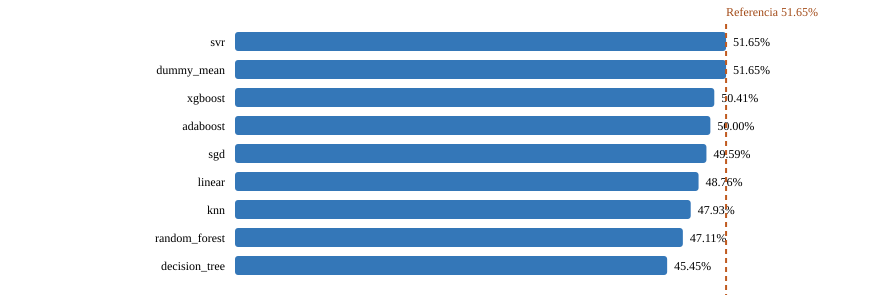

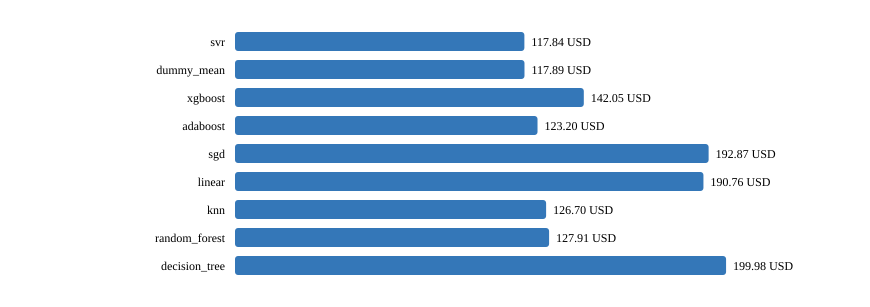

Modelo,Acierto TR,Acierto VA,RMSE VA USD,MAE VA USD,Sesgo,Correlación
svr,52.38%,51.65%,117.84,87.62,0.000,0.004
dummy_mean,52.38%,51.65%,117.89,87.66,0.000,No definida
xgboost,98.86%,50.41%,142.05,105.57,0.766,-0.104
adaboost,58.49%,50.00%,123.20,92.36,0.287,-0.027
sgd,67.81%,49.59%,192.87,152.77,0.793,-0.049
linear,67.70%,48.76%,190.76,150.77,0.847,-0.046
knn,58.28%,47.93%,126.70,93.87,0.267,0.057
random_forest,91.72%,47.11%,127.91,95.84,0.449,-0.127
decision_tree,100.00%,45.45%,199.98,150.37,0.967,-0.064


In [ ]:
mostrar_etapa(1)


## 3. Optimización · tres bloques temporales


Tabla o interpretación: 3. Optimización · tres bloques temporales

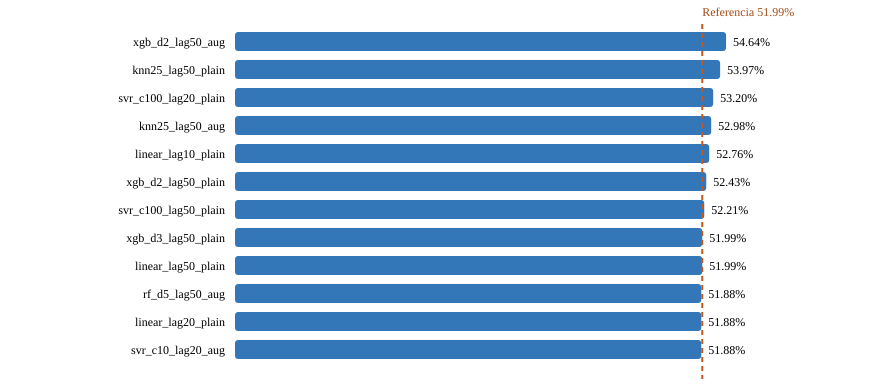

Configuración,Acierto medio,RMSE medio USD,Mejora pp,Supera referencia en todos los bloques
xgb_d2_lag50_aug,54.64%,130.24,+2.65,No
knn25_lag50_plain,53.97%,128.44,+1.99,No
svr_c100_lag20_plain,53.20%,129.28,+1.21,No
knn25_lag50_aug,52.98%,128.75,+0.99,No
linear_lag10_plain,52.76%,127.93,+0.77,No
xgb_d2_lag50_plain,52.43%,130.11,+0.44,No
svr_c100_lag50_plain,52.21%,128.55,+0.22,No
xgb_d3_lag50_plain,51.99%,131.86,-0.00,No
linear_lag50_plain,51.99%,132.48,-0.00,No
rf_d5_lag50_aug,51.88%,128.71,-0.11,No


In [ ]:
mostrar_etapa(2)


## 4. Candidato y estabilidad


Bloque,N,Acierto candidato,Referencia,Mejora pp
1,302,52.32%,52.98%,-0.66
2,302,59.93%,52.65%,+7.28
3,302,51.66%,50.33%,+1.32


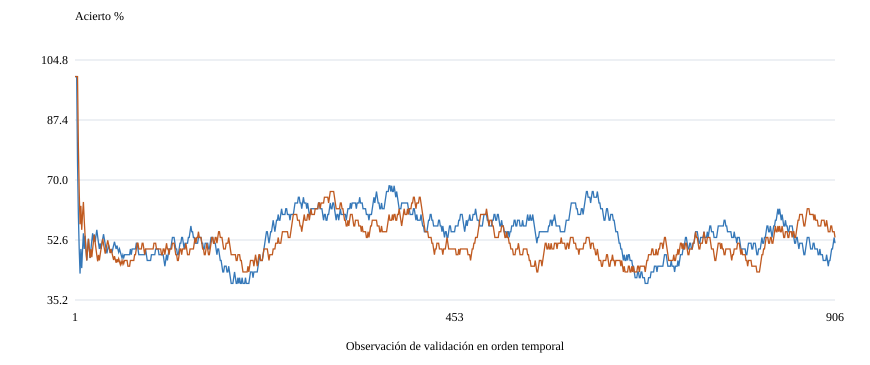

Tabla o interpretación: 4. Candidato y estabilidad

In [ ]:
mostrar_etapa(3)


## 5. Predicción frente al resultado · candidato


Tabla o interpretación: 5. Predicción frente al resultado · candidato

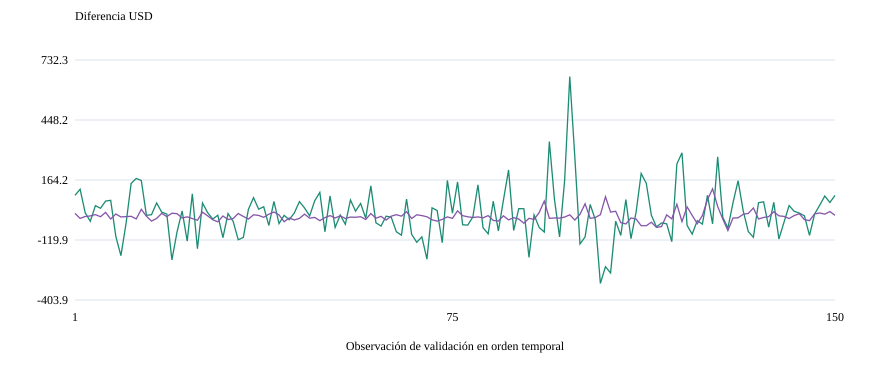

Tabla o interpretación: 5. Predicción frente al resultado · candidato

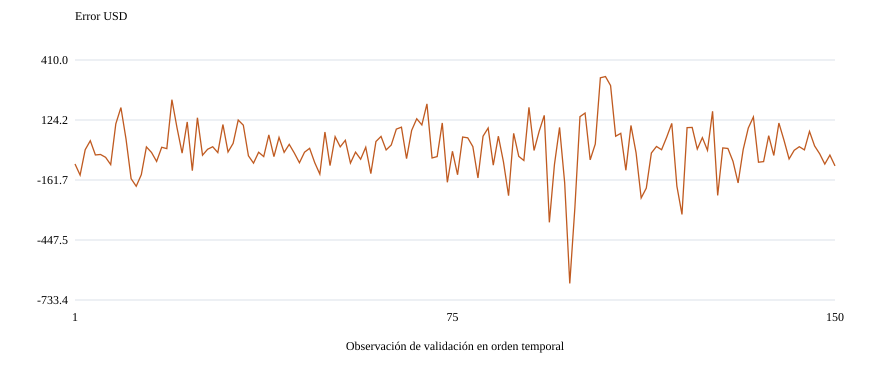

Resultado real / Predicción,Down,Up
Down,348,123
Up,288,147


In [ ]:
mostrar_etapa(4)


## 6. Lectura del resultado y siguiente decisión


In [ ]:
mostrar_etapa(5)


Tabla o interpretación: 6. Lectura del resultado y siguiente decisión

## Repetir entrenamiento y optimización (opcional)

Para repetir ambos experimentos desde los datos auditados, cambia `REENTRENAR` a `True` y ejecuta esta celda con el kernel `.venv`. Las ejecuciones nuevas se guardan juntas bajo `models/analisis/`; no se sobrescriben los experimentos previos. Después vuelve a ejecutar la celda de regeneración y las gráficas.

Esta operación sigue siendo exploratoria: usa la aproximación histórica de disponibilidad. Mantiene el test final reservado. Requiere las dependencias de `requirements-lock.txt` y los motores del repositorio. No activa modelos ni compra.


In [ ]:
REENTRENAR = False

if REENTRENAR:
    import sys
    from datetime import datetime, timezone
    if str(PROYECTO) not in sys.path:
        sys.path.insert(0, str(PROYECTO))
    from training import run as entrenar
    from optimize import run as optimizar
    carpeta = PROYECTO / "models/analisis" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f")
    entrenar(DATOS, PROYECTO / "config/experiments.json", carpeta / "original", proxy=True)
    optimizar(DATOS, carpeta / "optimizado")
    ORIGINAL = carpeta / "original/results.json"
    OPTIMIZADO = carpeta / "optimizado/results.json"
    print("Ejecución terminada. Regenera el análisis para actualizar las gráficas.")
else:
    print("Se conservan los resultados actuales. No se reentrenó.")
